# 0 · Data preprocessing

**Run this first.** It builds the training data every other notebook uses.

An upscaler learns from pairs: a small, damaged **LR** (low resolution) picture and the
clean **HR** (high resolution) picture it came from. This notebook makes those pairs:

1. **Collect** source pictures: photos (DIV2K, Flickr2K), YouTube clips, drawn desktop
   screens (`datasets/screens.py`) and your own screenshots in `datasets/raw/captures/`.
   With none of those on disk, it draws fake desktop screenshots instead, so the notebook
   always runs.
2. **Degrade** each source the way the stream does (`helpers/degrade.py`): shrink it,
   then compress it with H.264. A still image is first turned into a short moving clip
   (`helpers/motion.py`), because a stream is mostly moving frames.
3. **Crop** small patches out of each clip. Each LR patch has a few extra pixels (the
   **halo**) around it, like a tile in the browser. Flat patches, and ones the codec destroyed, are skipped.
4. **Save** the patches as `.npy` arrays plus a `manifest.json` in `datasets/upscale/`.

Train and validation data are split by *source* (a whole image or a whole video), never
by patch: patches of one picture look alike, and splitting them would make the
validation score look better than it really is.

In [1]:
"""Settings."""

from helpers import sources

CAPTURE_DIR = sources.RAW / "captures"        # your own screenshots
OUT_DIR = sources.ROOT / "upscale"            # where the patches are written
SYNTHETIC_DIR = OUT_DIR / "synthetic"         # drawn desktop frames

SCALE = 2                  # upscale factor
PATCH_HR = 128             # HR patch size; the LR core is PATCH_HR // SCALE = 64
HALO = 4                   # extra LR pixels around the core on every side
FRAMES_PER_PATCH = 8       # frames kept per patch (the crop stays still, the content moves)
PATCHES_PER_SOURCE = 16    # patches cut from each source
CROP_TRIES = 4             # attempts per patch before a flat source gives up
VAR_MIN = 24.0             # skip patches whose brightness varies less than this (flat areas)
MIN_LR_PSNR = 24.0         # skip patches the codec destroyed (LR vs a clean downscale, luma dB)
VAL_FRACTION = 0.2         # share of your own captures kept for validation
SEED = 0

# How many files of each dataset to use: "train" from its train.txt, "val" from its test.txt.
# One patch is about 0.5 MB, so these 1330 sources x 16 patches are about 11 GB. None means
# every file of that split - and draws nothing from the random generator, so adding a
# dataset at the end picks the same files for the ones before it. (Not the same
# degradations: the codec's threads make it differ a little run to run, and the first
# crop that turns out differently shifts every random choice after it.)
DATASETS = {
    "div2k": {"train": 200, "val": 50},
    "flickr2k": {"train": 200},
    "yt8m-videos": {"train": 300, "val": 100},
    "screens": {"train": None, "val": None},   # desktop screens, drawn by datasets/screens.py
}

# A still image becomes a 1 second clip of a 1280x720 window moving over it.
IMAGE_FPS = 30
CLIP_FRAMES = 30
WINDOW = (1280, 720)

# "stream": each source gets a random filter, bitrate and loop filter (and no codec for
# CLEAN_SHARE of them). "clean": a plain bicubic downscale, no codec - for comparison.
DEGRADATION = "stream"
CLEAN_SHARE = 0.1
DEBLOCK_SHARE = 0.5

# Drawn desktop frames: always written (other notebooks use one as a demo picture), and
# only trained on when there is no other data.
SYNTHESISE_IF_EMPTY = True
SYNTHETIC_FRAMES = 12
SYNTHETIC_SIZE = (960, 600)

PATCH_LR = PATCH_HR // SCALE
INPUT_LR = PATCH_LR + 2 * HALO
assert PATCH_HR % SCALE == 0
assert CLIP_FRAMES >= FRAMES_PER_PATCH

In [2]:
"""Imports and folders."""

import json
import time

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw

from helpers import degrade, motion

IMAGE_SUFFIXES = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
rng = np.random.default_rng(SEED)

CAPTURE_DIR.mkdir(parents=True, exist_ok=True)
SYNTHETIC_DIR.mkdir(parents=True, exist_ok=True)
print("datasets ", sources.ROOT)
print("output   ", OUT_DIR)

datasets  /home/henrik/desktop-streamer-ai/datasets
output    /home/henrik/desktop-streamer-ai/datasets/upscale


## 1. Collect source pictures

Download the datasets with:

```
uv run datasets/download.py div2k flickr2k
uv run datasets/download.py yt8m-videos --total 1000 --sequences 5
uv run datasets/screens.py
```

You can also put screenshots in `datasets/raw/captures/`. To take one frame per second
from a screen recording:

```
ffmpeg -i capture.mp4 -vf fps=1 datasets/raw/captures/frame_%04d.png
```

The datasets are photos and camera video, which teach general detail. The drawn screens
(`datasets/screens.py`: code, documents, terminals, spreadsheets, chat, file explorers,
settings, in real fonts) are what teach the model text and UI edges - and what it is
judged on for a desktop. Your own screenshots are the real thing; add as many as you can.

In [3]:
"""Draw a fake desktop frame: windows with title bars, text-like lines, and a noisy block."""

def synthesise_frame(size, rng):
    width, height = size
    background = tuple(int(v) for v in rng.integers(20, 60, size=3))
    frame = Image.new("RGB", size, background)
    draw = ImageDraw.Draw(frame)

    for y in range(height):  # wallpaper gradient
        shade = int(18 * y / height)
        draw.line([(0, y), (width, y)], fill=tuple(min(255, c + shade) for c in background))

    for _ in range(int(rng.integers(2, 5))):  # windows
        w = int(rng.integers(width // 4, width // 2))
        h = int(rng.integers(height // 4, height // 2))
        x = int(rng.integers(0, max(1, width - w)))
        y = int(rng.integers(0, max(1, height - h)))
        panel = tuple(int(v) for v in rng.integers(180, 250, size=3))
        accent = tuple(int(v) for v in rng.integers(40, 140, size=3))
        draw.rectangle([x, y, x + w, y + h], fill=panel, outline=accent, width=2)
        draw.rectangle([x, y, x + w, y + 22], fill=accent)  # title bar
        for i in range(3):  # window buttons
            draw.ellipse([x + w - 18 - i * 16, y + 6, x + w - 8 - i * 16, y + 16], fill=panel)

        ink = tuple(int(v) for v in rng.integers(0, 90, size=3))
        row = y + 34
        while row < y + h - 12:  # text-like lines
            length = int(rng.integers(w // 4, max(w // 4 + 1, w - 24)))
            draw.rectangle([x + 12, row, x + 12 + length, row + 4], fill=ink)
            row += int(rng.integers(10, 18))

    # a block of noise stands in for a video playing on screen
    nw, nh = width // 5, height // 5
    nx, ny = int(rng.integers(0, width - nw)), int(rng.integers(0, height - nh))
    frame.paste(Image.fromarray(rng.integers(0, 255, (nh, nw, 3), dtype=np.uint8)), (nx, ny))
    return frame

In [4]:
"""List every source: where it is, its split, and whether it is an image or a video."""

items = []
for name, wanted in DATASETS.items():
    for split, count in wanted.items():
        try:
            paths = sources.files(name, "test" if split == "val" else "train")
        except FileNotFoundError as error:
            print(f"  {name}: not on disk, skipped ({error})")
            break
        if count is not None and count < len(paths):
            paths = [paths[i] for i in sorted(rng.choice(len(paths), count, replace=False))]
        kind = "sequence" if name in sources.SEQUENCES else "image"
        items += [{"dataset": name, "split": split, "path": p, "kind": kind} for p in paths]

# The drawn frames use their own random generator, so drawing them does not change any
# other random choice in this notebook.
synthetic = sorted(SYNTHETIC_DIR.glob("synthetic_*.png"))
if len(synthetic) < SYNTHETIC_FRAMES:
    synthetic_rng = np.random.default_rng(SEED)
    synthetic = [SYNTHETIC_DIR / f"synthetic_{i:04d}.png" for i in range(SYNTHETIC_FRAMES)]
    for path in synthetic:
        synthesise_frame(SYNTHETIC_SIZE, synthetic_rng).save(path)

# Your captures, split here. With no datasets and no captures, the drawn frames instead.
own = sorted(p for p in CAPTURE_DIR.rglob("*") if p.suffix.lower() in IMAGE_SUFFIXES)
label = "captures"
if not own and not items and SYNTHESISE_IF_EMPTY:
    print(f"no datasets and no captures - training on the {len(synthetic)} drawn frames")
    own, label = synthetic, "synthetic"
order = rng.permutation(len(own))
n_val = max(1, round(len(own) * VAL_FRACTION)) if len(own) > 1 else 0
held_out = {own[i] for i in order[:n_val]}
items += [{"dataset": label, "split": "val" if p in held_out else "train", "path": p, "kind": "image"}
          for p in own]

if not items:
    raise RuntimeError(f"no datasets, no images in {CAPTURE_DIR}, and synthesis is off")

for split in ("train", "val"):
    counts = {}
    for item in items:
        if item["split"] == split:
            counts[item["dataset"]] = counts.get(item["dataset"], 0) + 1
    print(f"{split:5} {sum(counts.values()):4} sources  {counts}")

train 1100 sources  {'div2k': 200, 'flickr2k': 200, 'yt8m-videos': 300, 'screens': 400}
val    230 sources  {'div2k': 50, 'yt8m-videos': 100, 'screens': 80}


## 2. Degrade

Each source becomes a clip: a YouTube sequence already is one, and an image becomes
`CLIP_FRAMES` frames of a window sliding, zooming or standing still over it.

The **whole frame** then goes through the stream (shrink, 4:2:0 colour, H.264, decode),
not each patch on its own: a real encoder sees the whole screen, and its blocks and
bitrate depend on that.

Each source gets its own random settings (`degrade.sample`), written to the manifest so
results can later be split by bitrate or by kind of motion. A random run of
`FRAMES_PER_PATCH` frames is kept from each clip.

In [5]:
"""Make one source a clip, send it through the stream, keep a run of frames."""

def degradation_for(fps):
    if DEGRADATION == "clean":
        return degrade.Degradation(scale=SCALE, filter="bicubic", bpp=None, fps=fps)
    return degrade.sample(rng, scale=SCALE, fps=fps, clean=CLEAN_SHARE, deblock=DEBLOCK_SHARE)


def clip_of(item):
    """HR and LR frames (FRAMES_PER_PATCH, H, W, 3) of one source, and how they were made."""
    record = {}
    if item["kind"] == "sequence":
        frames, fps = sources.load_sequence(item["path"])
    else:
        image = sources.load_image(item["path"])
        shown = motion.sample(rng, (image.shape[1], image.shape[0]), CLIP_FRAMES, WINDOW)
        frames, fps = motion.render(image, shown), IMAGE_FPS
        record["motion"] = shown.as_dict()
    if len(frames) < FRAMES_PER_PATCH:
        raise ValueError(f"{item['path']}: only {len(frames)} frames")

    d = degradation_for(fps)
    hr, lr = degrade.degrade(frames, d)
    offset = int(rng.integers(0, len(hr) - FRAMES_PER_PATCH + 1))
    record.update(degradation=d.as_dict(), offset=offset)
    keep = slice(offset, offset + FRAMES_PER_PATCH)
    return hr[keep], lr[keep], record


hr_demo, lr_demo, demo_record = clip_of(items[0])
print(items[0]["dataset"], items[0]["path"].name)
print("HR", hr_demo.shape, " LR", lr_demo.shape)
print(demo_record)

div2k 0002.png
HR (8, 720, 1280, 3)  LR (8, 360, 640, 3)
{'motion': {'kind': 'slide', 'window': (1280, 720), 'frames': 30, 'start': (255, 309, 1280), 'end': (632, 338, 1280)}, 'degradation': {'scale': 2, 'filter': 'area', 'bpp': None, 'fps': 30, 'deblock': False}, 'offset': 6}


## 3. Crop patches

A patch is one spot of the screen, held still for `FRAMES_PER_PATCH` frames while the
content moves under it - exactly what one tile sees.

- The LR patch is `INPUT_LR` pixels: the core plus `HALO` pixels of context per side.
- The HR patch is the core only, `SCALE` times larger.
- Spots start on even LR pixels, because 4:2:0 colour is shared between pixel pairs.
- A spot is kept only if it is not flat (brightness variance above `VAR_MIN`).
- ...and only if the codec left something to learn from: its LR core, against a clean
  downscale of the HR, must score `MIN_LR_PSNR` dB or more (luma PSNR, mean over the
  frames). A clean downscale scores 30 dB or more; below about 22 dB the LR is grey blocks
  with nothing of the target left. At the bitrates drawn it is a safety net: it drops
  about 3% of the busy spots.

In [6]:
"""Cut patches at random places of one clip."""

LUMA = np.array([0.299, 0.587, 0.114], dtype=np.float32)


def lr_psnr(lr_patch, hr_patch):
    """How much of the LR core survived the stream: luma PSNR (dB) against a clean 2x2
    downscale of the HR, the mean over the frames."""
    core = lr_patch[:, HALO:HALO + PATCH_LR, HALO:HALO + PATCH_LR].astype(np.float32) @ LUMA
    clean = (hr_patch.astype(np.float32) @ LUMA).reshape(-1, PATCH_LR, SCALE, PATCH_LR, SCALE).mean(axis=(2, 4))
    mse = ((core - clean) ** 2).mean(axis=(1, 2))
    return float(np.mean(10 * np.log10(255 ** 2 / np.maximum(mse, 1e-10))))


def crops(hr, lr, rng):
    """[(LR (T, INPUT_LR, INPUT_LR, 3), HR (T, PATCH_HR, PATCH_HR, 3)), ...] of one clip, and
    how many spots were tried and skipped."""
    skipped = {"flat": 0, "destroyed": 0}
    height, width = lr.shape[1:3]
    if height < INPUT_LR or width < INPUT_LR:
        return [], skipped
    pairs = []
    for _ in range(PATCHES_PER_SOURCE * CROP_TRIES):
        if len(pairs) == PATCHES_PER_SOURCE:
            break
        y = 2 * int(rng.integers(0, (height - INPUT_LR) // 2 + 1))
        x = 2 * int(rng.integers(0, (width - INPUT_LR) // 2 + 1))
        y_hr, x_hr = (y + HALO) * SCALE, (x + HALO) * SCALE
        hr_patch = hr[:, y_hr:y_hr + PATCH_HR, x_hr:x_hr + PATCH_HR]
        if (hr_patch.astype(np.float32) @ LUMA).var(axis=(1, 2)).mean() < VAR_MIN:
            skipped["flat"] += 1
            continue
        lr_patch = lr[:, y:y + INPUT_LR, x:x + INPUT_LR]
        if lr_psnr(lr_patch, hr_patch) < MIN_LR_PSNR:
            skipped["destroyed"] += 1
            continue
        # .copy() so a kept patch does not keep the whole clip in memory
        pairs.append((lr_patch.copy(), hr_patch.copy()))
    return pairs, skipped


pairs, skipped = crops(hr_demo, lr_demo, rng)
print(f"{items[0]['path'].name}: {len(pairs)} patches kept, spots skipped {skipped}")

0002.png: 16 patches kept, spots skipped {'flat': 0, 'destroyed': 0}


In [7]:
"""Process every source and collect the patches per split."""

buckets = {split: {"lr": [], "hr": [], "files": [], "sources": []} for split in ("train", "val")}
skipped_spots = {"flat": 0, "destroyed": 0}

start = time.time()
for n, item in enumerate(items, 1):
    bucket = buckets[item["split"]]
    hr, lr, record = clip_of(item)
    base = {"captures": CAPTURE_DIR, "synthetic": SYNTHETIC_DIR}.get(item["dataset"], sources.RAW / item["dataset"])
    name = item["path"].relative_to(base).as_posix()
    pairs, skipped = crops(hr, lr, rng)
    for reason, count in skipped.items():
        skipped_spots[reason] += count
    if not pairs:
        print(f"  skipped {item['dataset']}/{name} - too flat or destroyed")
        continue
    first = len(bucket["lr"])
    bucket["lr"].extend(pair[0] for pair in pairs)
    bucket["hr"].extend(pair[1] for pair in pairs)
    bucket["files"].append(f"{item['dataset']}/{name}")
    # patches [first, last) of this split came from this source, made this way
    bucket["sources"].append({"dataset": item["dataset"], "file": name,
                              "patches": [first, len(bucket["lr"])], **record})
    if n % 50 == 0:
        print(f"  {n}/{len(items)} sources, {time.time() - start:.0f}s")

for split, bucket in buckets.items():
    bucket["lr"] = (np.stack(bucket["lr"]) if bucket["lr"]
                    else np.empty((0, FRAMES_PER_PATCH, INPUT_LR, INPUT_LR, 3), np.uint8))
    bucket["hr"] = (np.stack(bucket["hr"]) if bucket["hr"]
                    else np.empty((0, FRAMES_PER_PATCH, PATCH_HR, PATCH_HR, 3), np.uint8))
    print(f"{split:5} {len(bucket['sources']):4} sources {len(bucket['lr']):6} patches  "
          f"lr {bucket['lr'].shape}  hr {bucket['hr'].shape}")
print(f"spots skipped: {skipped_spots['flat']} flat, {skipped_spots['destroyed']} destroyed by the codec")
print(f"done in {time.time() - start:.1f}s")

if len(buckets["train"]["lr"]) == 0:
    raise RuntimeError("no training patches - lower VAR_MIN or MIN_LR_PSNR, or add more pictures")

  50/1330 sources, 17s


  100/1330 sources, 34s


  skipped div2k/DIV2K_train_HR/0604.png - too flat or destroyed


  150/1330 sources, 51s


  200/1330 sources, 68s


...

  skipped screens/test/00050.png - too flat or destroyed


  skipped screens/test/00067.png - too flat or destroyed


  skipped screens/test/00069.png - too flat or destroyed


train 1089 sources  17140 patches  lr (17140, 8, 72, 72, 3)  hr (17140, 8, 128, 128, 3)


val    225 sources   3523 patches  lr (3523, 8, 72, 72, 3)  hr (3523, 8, 128, 128, 3)
spots skipped: 8279 flat, 470 destroyed by the codec
done in 569.6s


## 4. Save

Four `uint8` arrays shaped `(patches, frames, height, width, 3)` and a manifest that
describes them. `uint8` is a quarter of the size of `float32`; the loaders divide by 255.

In [8]:
"""Write the arrays and the manifest."""

for split, bucket in buckets.items():
    np.save(OUT_DIR / f"{split}_lr.npy", bucket["lr"])
    np.save(OUT_DIR / f"{split}_hr.npy", bucket["hr"])

if DEGRADATION == "clean":
    summary = "bicubic downscale + 4:2:0, no codec"
else:
    summary = (f"stream: {'/'.join(degrade.FILTERS)} downscale, 4:2:0 BT.709, H.264 libx264 CBR "
               f"at {degrade.BPP_RANGE[0]}-{degrade.BPP_RANGE[1]} bits per pixel (log-uniform), "
               f"loop filter on for {DEBLOCK_SHARE:.0%}, no codec for {CLEAN_SHARE:.0%}, per source; "
               f"images as {CLIP_FRAMES}-frame moving clips; patches under {MIN_LR_PSNR} dB LR PSNR dropped")

manifest = {
    "created": time.strftime("%Y-%m-%dT%H:%M:%S"),
    "scale": SCALE,
    "patch_lr": PATCH_LR,
    "patch_hr": PATCH_HR,
    "halo": HALO,
    "input_lr": INPUT_LR,
    "frames_per_patch": FRAMES_PER_PATCH,
    "patches_per_source": PATCHES_PER_SOURCE,
    "var_min": VAR_MIN,
    "min_lr_psnr": MIN_LR_PSNR,
    "seed": SEED,
    "degradation": summary,
    "datasets": DATASETS,
    "image_clip": {"frames": CLIP_FRAMES, "fps": IMAGE_FPS, "window": list(WINDOW)},
    "splits": {
        split: {
            "patches": int(len(bucket["lr"])),
            "files": sorted(bucket["files"]),
            "lr": f"{split}_lr.npy",
            "hr": f"{split}_hr.npy",
            "sources": bucket["sources"],   # which patches came from which source, and how
        }
        for split, bucket in buckets.items()
    },
}
(OUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=4), encoding="utf-8")

written = sum(p.stat().st_size for p in OUT_DIR.glob("*.npy"))
print(f"{written / 1e6:.1f} MB written to {OUT_DIR}")

10695.8 MB written to /home/henrik/desktop-streamer-ai/datasets/upscale


## 5. Check the result

The LR and HR side of each patch must show the same content. If a crop or the halo were
off by a pixel, nothing would crash - the model would just train badly. So we look at a
few pairs, and also measure it: the HR patch shrunk down must match the LR core better
where it is than shifted one pixel in any direction.

reloaded (17140, 8, 72, 72, 3) (17140, 8, 128, 128, 3) uint8


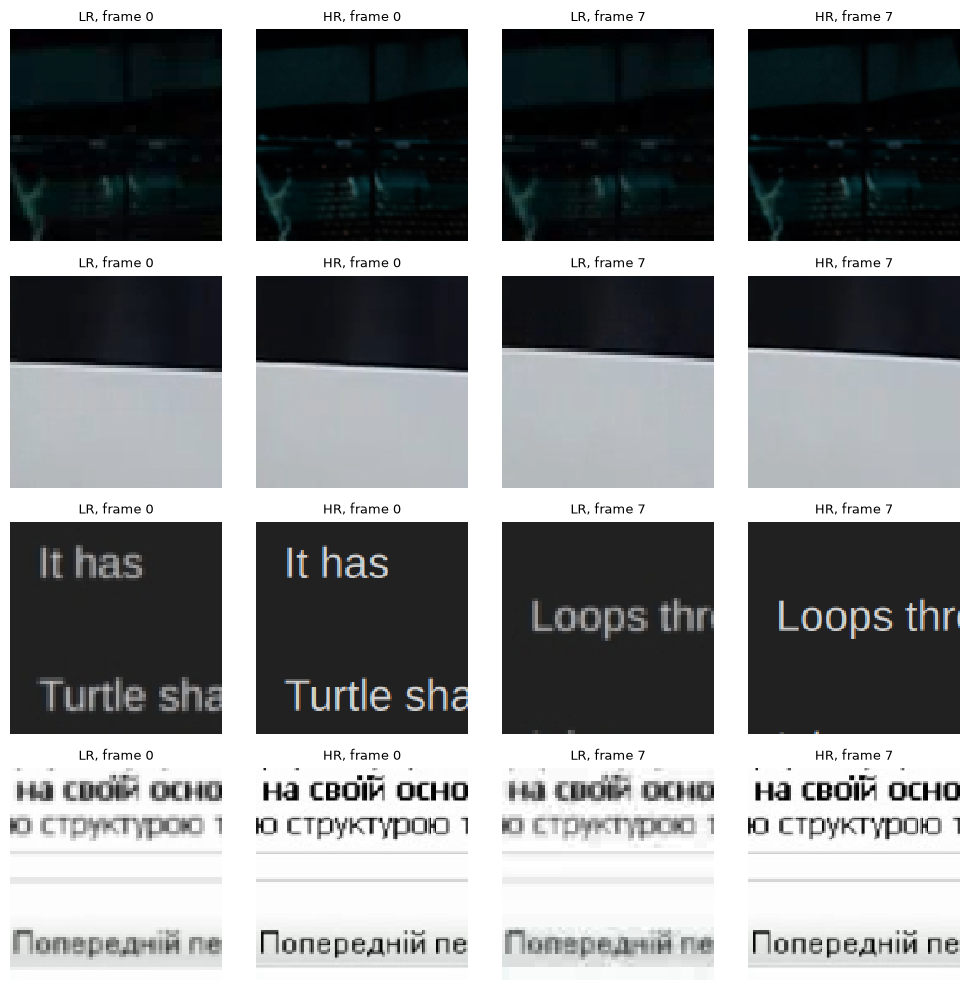

mean error: 3.09 in place, 8.28 or more one pixel off


In [9]:
"""Reload from disk, show a few pairs, and check they line up."""

manifest = json.loads((OUT_DIR / "manifest.json").read_text(encoding="utf-8"))
lr = np.load(OUT_DIR / manifest["splits"]["train"]["lr"], mmap_mode="r")
hr = np.load(OUT_DIR / manifest["splits"]["train"]["hr"], mmap_mode="r")
print("reloaded", lr.shape, hr.shape, lr.dtype)


def core(patch, dy=0, dx=0):
    """The LR core of a patch frame, optionally shifted inside the halo."""
    return patch[HALO + dy:HALO + dy + PATCH_LR, HALO + dx:HALO + dx + PATCH_LR]


rows = min(4, len(lr))
picks = np.random.default_rng(SEED).choice(len(lr), rows, replace=False)
last = lr.shape[1] - 1
fig, axes = plt.subplots(rows, 4, figsize=(10, 2.5 * rows), squeeze=False)
for row, index in enumerate(picks):
    for column, t in enumerate((0, last)):
        axes[row][2 * column].imshow(core(lr[index, t]), interpolation="nearest")
        axes[row][2 * column].set_title(f"LR, frame {t}", fontsize=9)
        axes[row][2 * column + 1].imshow(hr[index, t], interpolation="nearest")
        axes[row][2 * column + 1].set_title(f"HR, frame {t}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
plt.show()

if HALO:
    checked = np.random.default_rng(SEED).choice(len(lr), min(200, len(lr)), replace=False)
    shifts = [(dy, dx) for dy in (-1, 0, 1) for dx in (-1, 0, 1)]
    errors = np.zeros(len(shifts))
    for index in checked:
        t = int(index) % lr.shape[1]
        small = hr[index, t].astype(np.float32).reshape(PATCH_LR, SCALE, PATCH_LR, SCALE, 3).mean((1, 3))
        errors += [np.abs(core(lr[index, t], dy, dx).astype(np.float32) - small).mean() for dy, dx in shifts]
    errors /= len(checked)
    nearest_miss = min(e for e, shift in zip(errors, shifts) if shift != (0, 0))
    print(f"mean error: {errors[shifts.index((0, 0))]:.2f} in place, {nearest_miss:.2f} or more one pixel off")
    assert errors.argmin() == shifts.index((0, 0)), "LR and HR patches are misaligned"

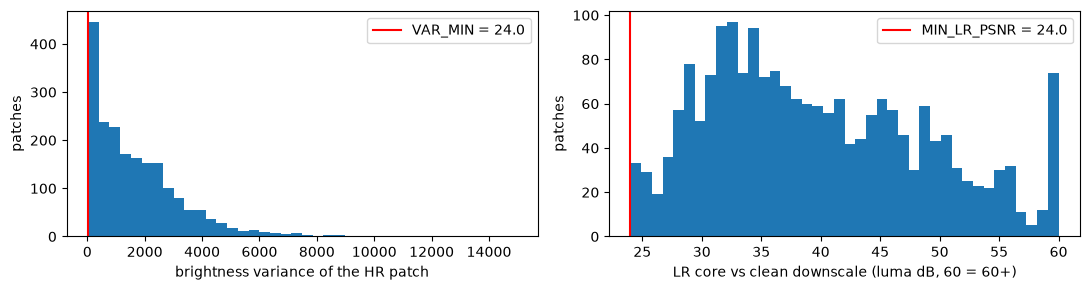

next: 1_upscale_dummy.ipynb


In [10]:
"""How busy and how damaged the kept patches are, against VAR_MIN and MIN_LR_PSNR."""

sample = np.sort(np.random.default_rng(SEED).choice(len(hr), min(2000, len(hr)), replace=False))
variance = (hr[sample].astype(np.float32) @ LUMA).var(axis=(2, 3)).mean(axis=1)
damage = np.minimum([lr_psnr(lr[i], hr[i]) for i in sample], 60)   # a near-perfect patch is off the scale

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, values, name, limit, label in [
        (axes[0], variance, "VAR_MIN", VAR_MIN, "brightness variance of the HR patch"),
        (axes[1], damage, "MIN_LR_PSNR", MIN_LR_PSNR, "LR core vs clean downscale (luma dB, 60 = 60+)")]:
    ax.hist(values, bins=40)
    ax.axvline(limit, color="red", label=f"{name} = {limit}")
    ax.set_xlabel(label)
    ax.set_ylabel("patches")
    ax.legend()
fig.tight_layout()
plt.show()

print("next: 1_upscale_dummy.ipynb")